## Agenda

- How do I choose **which model to use** for my supervised learning task?
- How do I choose the **best tuning parameters** for that model?
- How do I estimate the **likely performance of my model** on out-of-sample data?

## Review

- Classification task: Predicting the survival of a Titanic passenger (0 = Did not survive, 1 = Survived)
- Used classification models: KNN (with various values of K) and Logistic Regression
- Need a way to choose between the models

**Solution:** Model evaluation procedures

## Evaluation procedure #1: Train and test on the entire dataset

1. Train the model on the **entire dataset**.
2. Test the model on the **same dataset**, and evaluate how well we did by comparing the **predicted** response values with the **true** response values.

In [1]:
# read in the titanic data using seaborn
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler

titanic = sns.load_dataset('titanic')

# feature selection
feature_cols = ['pclass', 'sex', 'age', 'fare', 'sibsp', 'parch']

# handle missing values (fill missing age and fare with median)
titanic['age'] = titanic['age'].fillna(titanic['age'].median())
titanic['fare'] = titanic['fare'].fillna(titanic['fare'].median())

# encode categorical 'sex' feature (male: 0, female: 1)
titanic['sex'] = titanic['sex'].map({'male': 0, 'female': 1})

# create X (features) and y (response)
X = titanic[feature_cols].values
y = titanic['survived'].values

# scale features so KNN distance calculation isn't dominated by 'fare'
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X.shape)
print(y.shape)

(891, 6)
(891,)


- Known as **training accuracy** when you train and test the model on the same data

### KNN on the entire dataset: K=1 through K=5

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

# KNN (K=1) on entire dataset
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_scaled, y)
y_pred = knn.predict(X_scaled)
print("K=1 Training Accuracy:", metrics.accuracy_score(y, y_pred))

# KNN (K=2) on entire dataset
knn = KNeighborsClassifier(n_neighbors=2)
knn.fit(X_scaled, y)
y_pred = knn.predict(X_scaled)
print("K=2 Training Accuracy:", metrics.accuracy_score(y, y_pred))

# KNN (K=3) on entire dataset
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_scaled, y)
y_pred = knn.predict(X_scaled)
print("K=3 Training Accuracy:", metrics.accuracy_score(y, y_pred))

# KNN (K=4) on entire dataset
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_scaled, y)
y_pred = knn.predict(X_scaled)
print("K=4 Training Accuracy:", metrics.accuracy_score(y, y_pred))

# KNN (K=5) on entire dataset
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_scaled, y)
y_pred = knn.predict(X_scaled)
print("K=5 Training Accuracy:", metrics.accuracy_score(y, y_pred))

K=1 Training Accuracy: 0.9753086419753086
K=2 Training Accuracy: 0.8855218855218855
K=3 Training Accuracy: 0.8799102132435466
K=4 Training Accuracy: 0.8653198653198653
K=5 Training Accuracy: 0.8630751964085297


## Evaluation procedure #2: Train/test split

1. Split the dataset into two pieces: a **training set** and a **testing set**.
2. Train the model on the **training set**.
3. Test the model on the **testing set**, and evaluate how well we did.

In [3]:
# print the shapes of X and y
print(X.shape)
print(y.shape)

(891, 6)
(891,)


In [4]:
# STEP 1: split X and y into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=4)

# scale X_train and X_test using training parameters
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# print the shapes of the new X objects
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(534, 6)
(357, 6)


In [6]:
# print the shapes of the new y objects
print(y_train.shape)
print(y_test.shape)

(534,)
(357,)


### Train/Test Split: KNN (K=1 through K=5)

In [7]:
# KNN with K=1
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("K=1 Testing Accuracy:", metrics.accuracy_score(y_test, y_pred))

K=1 Testing Accuracy: 0.7927170868347339


In [8]:
# KNN with K=2
knn = KNeighborsClassifier(n_neighbors=2)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("K=2 Testing Accuracy:", metrics.accuracy_score(y_test, y_pred))

K=2 Testing Accuracy: 0.7899159663865546


In [9]:
# KNN with K=3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("K=3 Testing Accuracy:", metrics.accuracy_score(y_test, y_pred))

K=3 Testing Accuracy: 0.8375350140056023


In [10]:
# KNN with K=4
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("K=4 Testing Accuracy:", metrics.accuracy_score(y_test, y_pred))

K=4 Testing Accuracy: 0.8151260504201681


In [11]:
# KNN with K=5
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("K=5 Testing Accuracy:", metrics.accuracy_score(y_test, y_pred))

K=5 Testing Accuracy: 0.834733893557423


### Repeat for Logistic Regression

In [12]:
# STEP 2: train the model on the training set
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [13]:
# STEP 3: make predictions on the testing set
y_pred = logreg.predict(X_test_scaled)

# compare actual response values (y_test) with predicted response values (y_pred)
print("Logistic Regression Testing Accuracy:", metrics.accuracy_score(y_test, y_pred))

Logistic Regression Testing Accuracy: 0.834733893557423


Can we locate an even better value for K?

In [14]:
# try K=1 through K=30 and record testing accuracy
k_range = list(range(1, 30))
scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    acc = metrics.accuracy_score(y_test, y_pred)
    scores.append(acc)
    print(f"K = {k:2d}: {acc}")

K =  1: 0.7927170868347339
K =  2: 0.7899159663865546
K =  3: 0.8375350140056023
K =  4: 0.8151260504201681
K =  5: 0.834733893557423
K =  6: 0.8179271708683473
K =  7: 0.8235294117647058
K =  8: 0.8291316526610645
K =  9: 0.8319327731092437
K = 10: 0.8375350140056023
K = 11: 0.8319327731092437
K = 12: 0.8263305322128851
K = 13: 0.8263305322128851
K = 14: 0.834733893557423
K = 15: 0.8319327731092437
K = 16: 0.834733893557423
K = 17: 0.8291316526610645
K = 18: 0.8291316526610645
K = 19: 0.8235294117647058
K = 20: 0.8263305322128851
K = 21: 0.8319327731092437
K = 22: 0.8263305322128851
K = 23: 0.834733893557423
K = 24: 0.8375350140056023
K = 25: 0.8319327731092437
K = 26: 0.8403361344537815
K = 27: 0.8319327731092437
K = 28: 0.834733893557423
K = 29: 0.8319327731092437


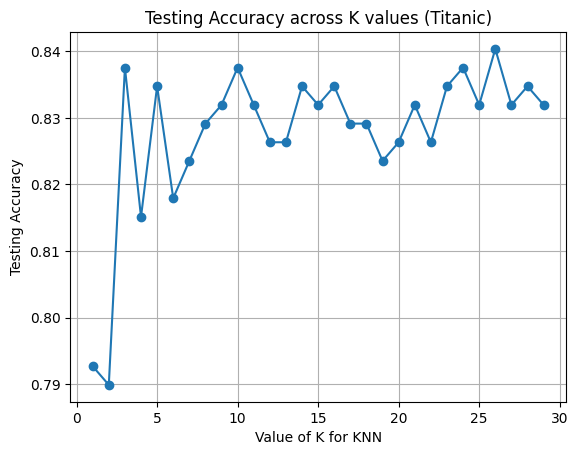

In [15]:
# import Matplotlib (scientific plotting library)
import matplotlib.pyplot as plt

# allow plots to appear within the notebook
%matplotlib inline

# plot the relationship between K and testing accuracy
plt.plot(k_range, scores, marker='o')
plt.xlabel('Value of K for KNN')
plt.ylabel('Testing Accuracy')
plt.title('Testing Accuracy across K values (Titanic)')
plt.grid(True)
plt.show()

- **Training accuracy** rises as model complexity increases
- **Testing accuracy** penalizes models that are too complex or not complex enough
- For KNN models, complexity is determined by the **value of K** (lower value = more complex)

### Observations & Conclusion (Tested across K = 1 to 29)

- **Overfitting at Very Low K ($K = 1, 2$):** Testing accuracy drops to its lowest point ($\approx 79.0\% - 79.3\%$). At $K=1$, the model memorizes local noise and outliers from individual passenger profiles rather than true general survival patterns.
- **Initial Spike ($K = 3$):** Accuracy jumps sharply to $\approx 83.75\%$, showing that introducing even minimal neighborhood consensus significantly filters out single-point anomalies.
- **Mid-Range Stability ($K \approx 7$ to $20$):** The accuracy fluctuates steadily within the $82.5\% - 83.7\%$ range, providing a smooth balance between passenger class, sex, and fare signals.
- **Global Peak ($K = 26$):** Unlike smaller datasets where accuracy often drops sharply past $K=20$, here testing accuracy achieves its highest score at **$K = 26$** ($\approx 84.03\%$). Larger neighborhoods effectively generalize general passenger survival likelihood.
- **Model Selection Verdict:** While $K = 26$ produces the top test score on this specific split, using **K-fold cross-validation** across $K \in [1, 30]$ is recommended before choosing the final model parameter to ensure this peak is not an artifact of the single random split.

## Making predictions on out-of-sample data

In [16]:
# Train the final model using the best K value
final_scaler = StandardScaler()
X_final_scaled = final_scaler.fit_transform(X)

knn = KNeighborsClassifier(n_neighbors=26)
knn.fit(X_final_scaled, y)

# Make predictions for new passengers
# Format: [pclass, sex, age, fare, sibsp, parch]

raw_samples = [
    [1, 1, 28, 100.0, 0, 0],
    [3, 0, 22, 7.25, 1, 0]
]

# Scale new samples using the same scaler
scaled_samples = final_scaler.transform(raw_samples)

# Predict survival
predictions = knn.predict(scaled_samples)

print("Predictions:", predictions)

Predictions: [1 0]


## Downsides of train/test split?

- Provides a **high-variance estimate** of out-of-sample accuracy
- **K-fold cross-validation** overcomes this limitation
- But, train/test split is still useful because of its **flexibility and speed**